# Rating ATP tennis players with skillgraph

Seven seasons of real tour-level results (2019–2025), rated one match at a time with TrueSkill 1.
Data: Jeff Sackmann's `tennis_atp` (CC BY-NC-SA 4.0), via its archival mirror.

```bash
pip install git+https://github.com/Tahahaha7/skillgraph  pandas matplotlib
```

In [1]:
import time
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rc

import skillgraph as sg
from skillgraph import TS1, Match, Rating

plt.style.use("seaborn-v0_8")
rc('text', usetex=True)
rc('font', family='serif')
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titlesize": 22, "axes.labelsize": 16,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 13})
pd.set_option("display.width", 200)
BLUE, ORANGE, RED, GREEN, PURPLE, GREY = "#4C72B0", "#DD8452", "#C44E52", "#55A868", "#8172B2", "#8C8C8C"

## 1. Load seven seasons

In [2]:
YEARS = range(2019, 2026)
DATA = Path("data")
DATA.mkdir(exist_ok=True)
MIRROR = "https://huggingface.co/datasets/Aneeshers/tennis-sackmann-archive/resolve/main/atp/"
for y in YEARS:
    f = DATA / f"atp_matches_{y}.csv"
    if not f.exists():
        urlretrieve(MIRROR + f.name, f)

df = pd.concat([pd.read_csv(DATA / f"atp_matches_{y}.csv", low_memory=False) for y in YEARS], ignore_index=True)
df = df[~df.score.astype(str).str.contains("W/O|DEF", case=False)]        # walkovers are not played matches
df["date"] = pd.to_datetime(df.tourney_date.astype(str))
df = df.sort_values(["date", "tourney_id", "match_num"]).reset_index(drop=True)
names = pd.concat([df.set_index("winner_id").winner_name, df.set_index("loser_id").loser_name]).groupby(level=0).last()
matches = [Match([[w], [l]], ranks=[0, 1]) for w, l in zip(df.winner_id, df.loser_id)]   # winner's team first
print(f"{len(df):,} matches, {names.size:,} players, {df.date.min():%b %Y} to {df.date.max():%b %Y}")

18,790 matches, 942 players, Dec 2018 to Dec 2025


## 2. Defaults were set for video games: tune them on tennis

Tennis has no draws (`draw_probability=0`). The two other settings matter: performance noise $\beta$
(how much a single match says) and skill drift $\tau$ (how fast players change). We score each pair
by log-loss on 2021–2023, after warming up on 2019–2020. Seasons 2024–2025 stay untouched for the
final test.

best: beta = $3\sigma$, tau = $\sigma/5$


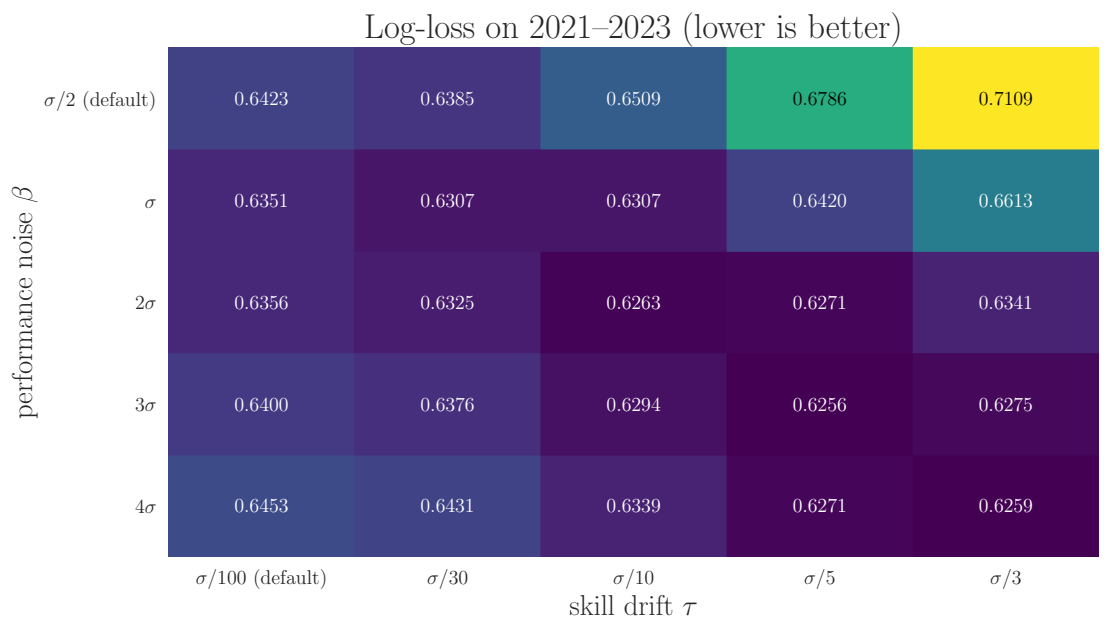

In [3]:
s = 25 / 3
betas = {r"$\sigma/2$ (default)": s / 2, r"$\sigma$": s, r"$2\sigma$": 2 * s, r"$3\sigma$": 3 * s, r"$4\sigma$": 4 * s}
taus = {r"$\sigma/100$ (default)": s / 100, r"$\sigma/30$": s / 30, r"$\sigma/10$": s / 10, r"$\sigma/5$": s / 5, r"$\sigma/3$": s / 3}
tune_window = ((df.date >= "2021-01-01") & (df.date < "2024-01-01")).to_numpy()
test_window = (df.date >= "2024-01-01").to_numpy()

def log_loss(model, window):
    probs = np.array(model.rate_matches(matches, with_probabilities=True).probabilities)
    return -np.mean(np.log(probs[window]))

grid = pd.DataFrame({tl: {bl: log_loss(TS1(beta=b, tau=t, draw_probability=0.0), tune_window) for bl, b in betas.items()}
                     for tl, t in taus.items()})
best_beta, best_tau = grid.stack().idxmin()
tuned = TS1(beta=betas[best_beta], tau=taus[best_tau], draw_probability=0.0)

fig, ax = plt.subplots(figsize=(10, 5.5))
im = ax.imshow(grid.to_numpy(), cmap="viridis", aspect="auto")
ax.set_xticks(range(len(taus))); ax.set_xticklabels(list(taus)); ax.set_yticks(range(len(betas))); ax.set_yticklabels(list(betas))
lo, hi = grid.to_numpy().min(), grid.to_numpy().max()
for i in range(len(betas)):
    for j in range(len(taus)):
        v = grid.iat[i, j]
        ax.text(j, i, f"{v:.4f}", ha="center", va="center", fontsize=13, color="white" if (v - lo) / (hi - lo) < 0.6 else "black")
ax.set_xlabel(r"skill drift $\tau$"); ax.set_ylabel(r"performance noise $\beta$"); ax.grid(False)
ax.set_title("Log-loss on 2021–2023 (lower is better)")
print(f"best: beta = {best_beta}, tau = {best_tau}")

Tennis is far noisier and drifts faster than the defaults assume. A large $\beta$ relative to the
prior $\sigma$ also means new players are more alike than the default prior says, so a single match
changes a rating less. The ridge in the heatmap shows $\beta$ and $\tau$ trading off. Everything below
uses the best cell.

## 3. The leaderboard at the end of 2025

In [4]:
t0 = time.time()
final = tuned.rate_matches(matches).ratings
print(f"rated {len(matches):,} matches in {time.time() - t0:.1f} s")

played = pd.concat([df.winner_id, df.loser_id]).value_counts()
last_rank = pd.concat([df[["winner_id", "winner_rank", "date"]].set_axis(["id", "rank", "date"], axis=1),
                       df[["loser_id", "loser_rank", "date"]].set_axis(["id", "rank", "date"], axis=1)]
                      ).sort_values("date").groupby("id")["rank"].last()
board = pd.DataFrame({
    "player": names,
    "mu": {p: r.mu for p, r in final.items()},
    "sigma": {p: r.sigma for p, r in final.items()},
    "score": {p: r.conservative() for p, r in final.items()},
    "matches": played,
    "ATP rank at last match": last_rank,
}).dropna(subset=["mu"]).sort_values("score", ascending=False)
board.head(15).round(2).reset_index(drop=True)

rated 18,790 matches in 0.2 s


,player,mu,sigma,score,matches,ATP rank at last match
0,Jannik Sinner,115.55,10.52,84.00,407,2.0
1,Carlos Alcaraz,106.27,10.06,76.10,345,1.0
2,Novak Djokovic,86.69,9.75,57.43,383,5.0
3,Jack Draper,72.52,9.21,44.90,169,5.0
4,Alexander Zverev,72.40,9.25,44.64,475,3.0
5,Felix Auger Aliassime,70.46,9.20,42.87,419,8.0
6,Taylor Fritz,70.00,9.15,42.55,441,6.0
7,Alex De Minaur,68.66,9.30,40.76,426,7.0
8,Daniil Medvedev,60.98,8.92,34.23,473,13.0
9,Lorenzo Musetti,61.35,9.09,34.08,310,9.0


The leaderboard uses the conservative score $\mu - 3\sigma$. A player who stopped playing keeps the
rating of his last match (Federer, Nadal), with a $\sigma$ that only grows through drift.

## 4. Seven seasons of the top players

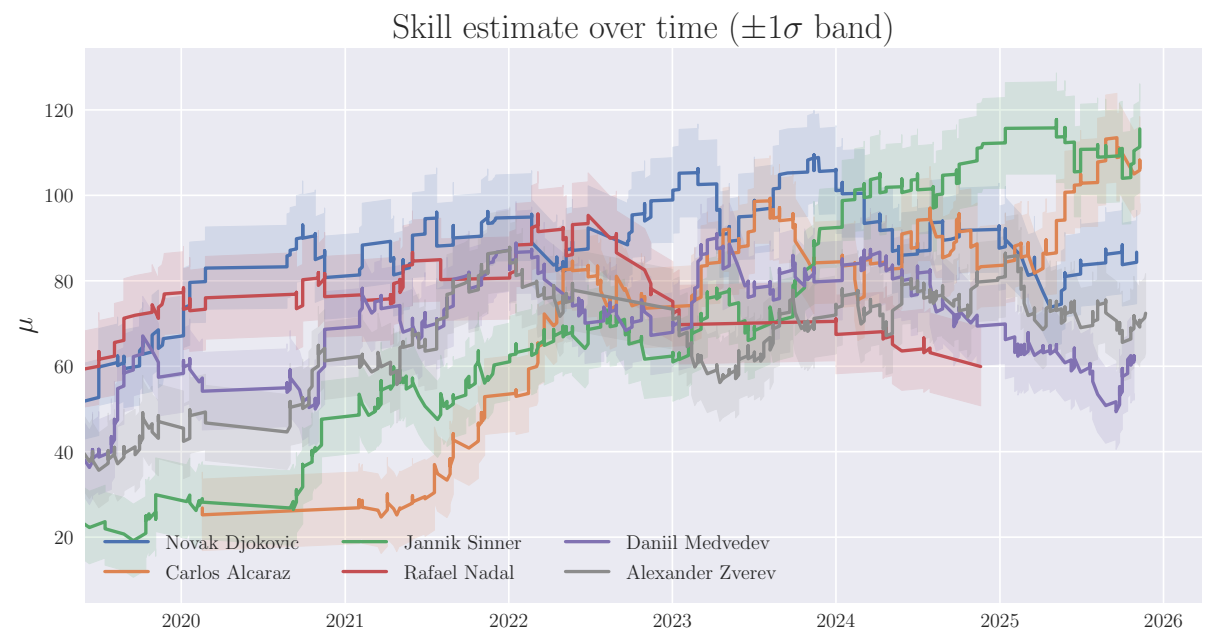

In [5]:
track = ["Novak Djokovic", "Carlos Alcaraz", "Jannik Sinner", "Rafael Nadal", "Daniil Medvedev", "Alexander Zverev"]
ids = {names[names == n].index[0]: n for n in track}
history = {p: [] for p in ids}
live = {}
for m, date in zip(matches, df.date):
    teams = [[live.get(p, tuned.create_rating()) for p in t] for t in m.teams]
    for t_ids, new in zip(m.teams, tuned.rate(teams, m.ranks)):
        for p, r in zip(t_ids, new):
            live[p] = r
            if p in history:
                history[p].append((date, r.mu, r.sigma))

fig, ax = plt.subplots(figsize=(12, 6))
for (p, name), c in zip(ids.items(), [BLUE, ORANGE, GREEN, RED, PURPLE, GREY]):
    d, mu, sd = map(np.array, zip(*history[p]))
    ax.plot(d, mu, color=c, lw=2, label=name)
    ax.fill_between(d, mu - sd, mu + sd, color=c, alpha=0.15)
ax.set_xlim(pd.Timestamp("2019-06-01"), None)
ax.set_title(r"Skill estimate over time ($\pm 1\sigma$ band)")
ax.set_ylabel(r"$\mu$")
ax.legend(ncol=3, loc="lower left");

## 5. Where does the tour sit?

With this much drift, uncertainty does not keep shrinking with experience: it settles where drift and
evidence balance, around $\sigma \approx 9$, even for players with 400 matches in the data.

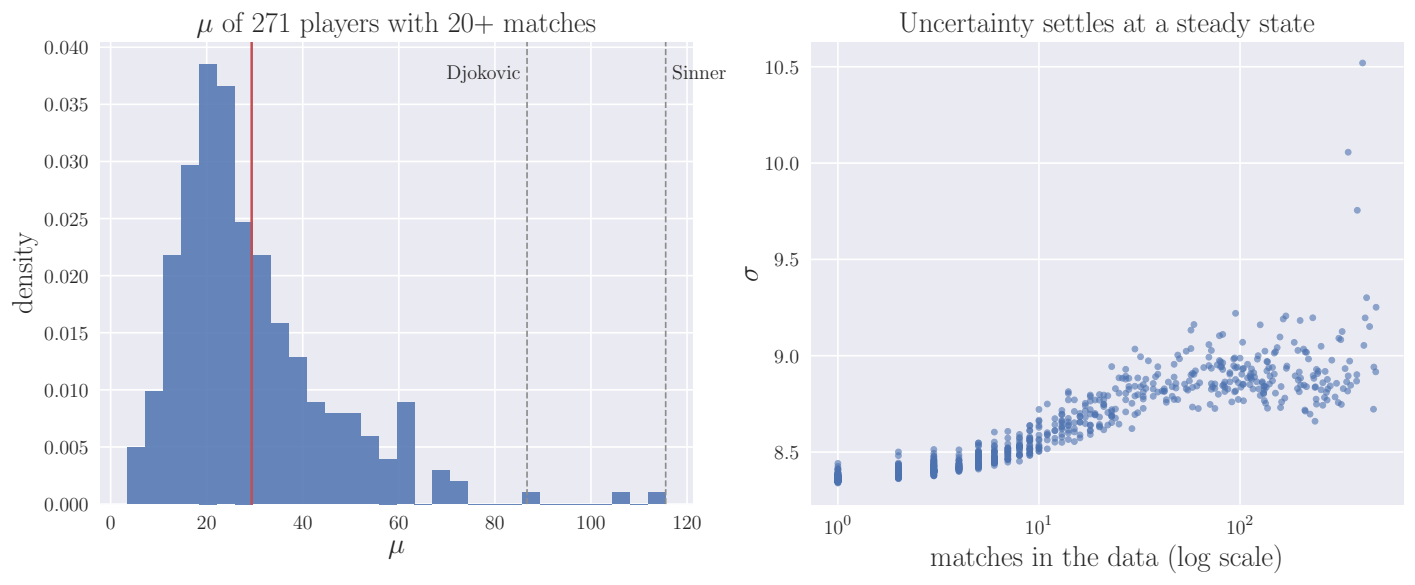

In [6]:
regular = board[board.matches >= 20]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
a1.hist(regular.mu, bins=30, density=True, color=BLUE, alpha=0.85)
a1.axvline(regular.mu.mean(), color=RED, lw=1.5)
for name, ha in [("Novak Djokovic", "right"), ("Jannik Sinner", "left")]:
    x = board.loc[board.player == name, "mu"].iloc[0]
    a1.axvline(x, color=GREY, lw=1, ls="--")
    a1.text(x, a1.get_ylim()[1] * 0.92, (" " if ha == "left" else "") + name.split()[-1] + (" " if ha == "right" else ""), ha=ha, fontsize=12)
a1.set_title(rf"$\mu$ of {len(regular)} players with 20+ matches", fontsize=18); a1.set_xlabel(r"$\mu$"); a1.set_ylabel("density")
a2.scatter(board.matches, board.sigma, s=12, color=BLUE, alpha=0.6)
a2.set_xscale("log")
a2.set_title("Uncertainty settles at a steady state", fontsize=18); a2.set_xlabel("matches in the data (log scale)"); a2.set_ylabel(r"$\sigma$");

## 6. Out-of-sample test: 2024–2025

Every match from 2024 on is predicted before it is rated. Baselines: Elo (with its $K$ chosen on
2021–2023 the same way) and simply backing the higher official ATP ranking.

In [7]:
def elo_prob(ra, rb):
    return 1 / (1 + 10 ** ((rb - ra) / 400))

def run_elo(k):
    elo, probs = {}, []
    for w, l in zip(df.winner_id, df.loser_id):
        ew, el = elo.get(w, 1500.0), elo.get(l, 1500.0)
        p = elo_prob(ew, el)
        probs.append(p)
        elo[w], elo[l] = ew + k * (1 - p), el - k * (1 - p)
    return np.array(probs)

elo_runs = {k: run_elo(k) for k in (16, 24, 32, 48, 64)}
best_k = min(elo_runs, key=lambda k: -np.mean(np.log(elo_runs[k][tune_window])))

p_default = np.array(TS1(draw_probability=0.0).rate_matches(matches, with_probabilities=True).probabilities)
p_tuned = np.array(tuned.rate_matches(matches, with_probabilities=True).probabilities)
has_rank = df.winner_rank.notna() & df.loser_rank.notna()
rank_right = (df.winner_rank < df.loser_rank)[test_window & has_rank].mean()

def summary(p):
    q = p[test_window]
    return {"accuracy": np.mean(q > 0.5), "log-loss": -np.mean(np.log(q))}

rows = {"TrueSkill, defaults": summary(p_default), "TrueSkill, tuned": summary(p_tuned),
        f"Elo, K = {best_k} (best of 16-64)": summary(elo_runs[best_k])}
if best_k != 32:
    rows["Elo, K = 32"] = summary(elo_runs[32])
rows["higher ATP rank wins"] = {"accuracy": rank_right, "log-loss": np.nan}
pd.DataFrame(rows).T.round(4)

,accuracy,log-loss
"TrueSkill, defaults",0.6252,0.6414
"TrueSkill, tuned",0.6362,0.6266
"Elo, K = 32 (best of 16-64)",0.6349,0.6281
higher ATP rank wins,0.6411,NaN


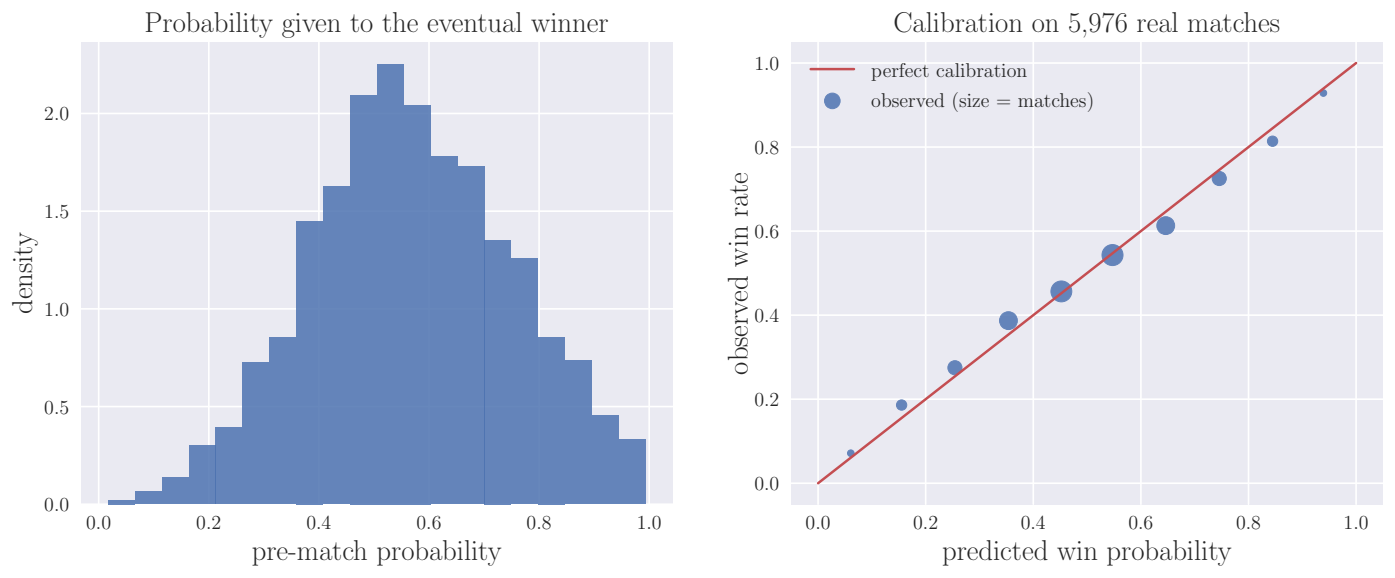

In [8]:
p = p_tuned[test_window]
p_all = np.concatenate([p, 1 - p]); y_all = np.concatenate([np.ones_like(p), np.zeros_like(p)])   # favourite and underdog of every match
edges = np.linspace(0, 1, 11)
mid, rate, n = [], [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    sel = (p_all >= lo) & (p_all < hi)
    if sel.sum() >= 50:
        mid.append(p_all[sel].mean()); rate.append(y_all[sel].mean()); n.append(sel.sum())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
a1.hist(p, bins=20, density=True, color=BLUE, alpha=0.85)
a1.set_title("Probability given to the eventual winner", fontsize=18); a1.set_xlabel("pre-match probability"); a1.set_ylabel("density")
a2.plot([0, 1], [0, 1], color=RED, lw=1.5, label="perfect calibration")
a2.scatter(mid, rate, s=np.array(n) / 15, color=BLUE, alpha=0.85, label="observed (size = matches)")
a2.set_title(f"Calibration on {test_window.sum():,} real matches", fontsize=18); a2.set_xlabel("predicted win probability"); a2.set_ylabel("observed win rate"); a2.legend();

## 7. The biggest upsets of 2024–2025, as the model saw them

In [9]:
ev = df[test_window].copy()
ev["p_winner"] = p
cols = ["date", "tourney_name", "round", "winner_name", "loser_name", "score", "p_winner"]
ev.nsmallest(8, "p_winner")[cols].assign(date=lambda d: d.date.dt.date).round(3).reset_index(drop=True)

,date,tourney_name,round,winner_name,loser_name,score,p_winner
0,2024-03-04,Indian Wells Masters,R32,Luca Nardi,Novak Djokovic,6-4 3-6 6-3,0.017
1,2025-06-16,Halle,R16,Alexander Bublik,Jannik Sinner,3-6 6-3 6-4,0.033
2,2025-10-01,Shanghai Masters,R32,Tallon Griekspoor,Jannik Sinner,6-7(3) 7-5 3-2 RET,0.041
3,2025-10-27,Paris Masters,R32,Cameron Norrie,Carlos Alcaraz,4-6 6-3 6-4,0.046
4,2024-08-26,Us Open,R64,Botic Van De Zandschulp,Carlos Alcaraz,6-1 7-5 6-4,0.059
5,2025-02-17,Rio de Janeiro,QF,Francisco Comesana,Alexander Zverev,4-6 6-3 6-4,0.061
6,2025-06-30,Wimbledon,R128,Nikoloz Basilashvili,Lorenzo Musetti,6-2 4-6 7-5 6-1,0.066
7,2024-02-19,Rio De Janeiro,R32,Thiago Monteiro,Carlos Alcaraz,1-1 RET,0.072


## 8. Surfaces

Rating each surface separately shows who the specialists are. Each bar is the player's rating at his
last match on that surface (Nadal's grass rating dates from 2022), so the bars mix points in time.

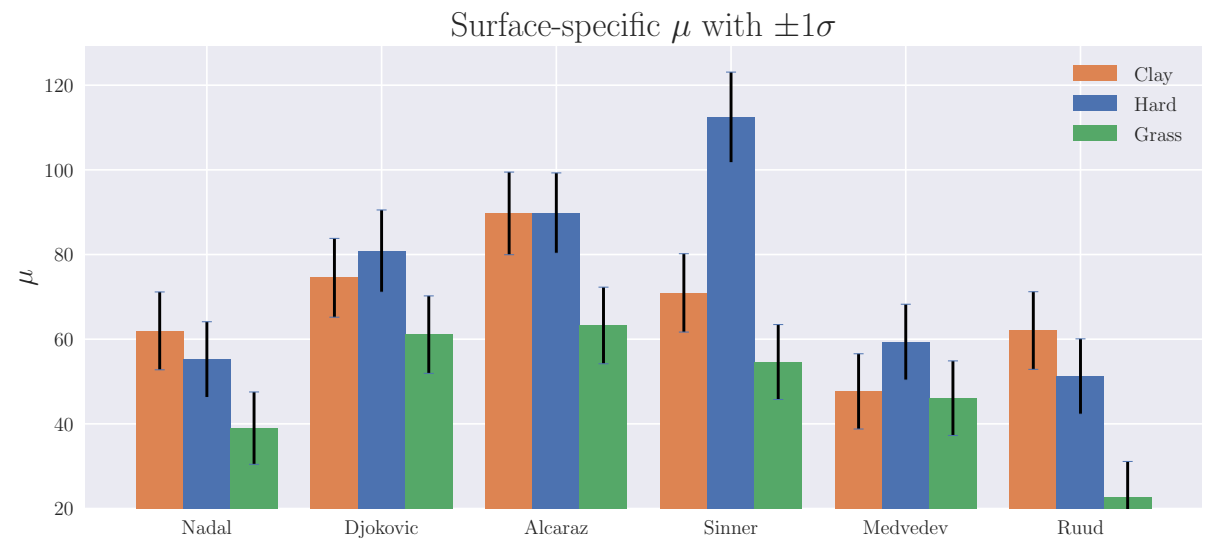

In [10]:
surface_rating = {}
for surf in ["Clay", "Hard", "Grass"]:
    sub = df[df.surface == surf]
    surface_rating[surf] = TS1(beta=tuned.beta, tau=tuned.tau, draw_probability=0.0).rate_matches(
        [Match([[w], [l]], ranks=[0, 1]) for w, l in zip(sub.winner_id, sub.loser_id)]).ratings

show = ["Rafael Nadal", "Novak Djokovic", "Carlos Alcaraz", "Jannik Sinner", "Daniil Medvedev", "Casper Ruud"]
x = np.arange(len(show)); width = 0.27
fig, ax = plt.subplots(figsize=(12, 5))
for k, (surf, c) in enumerate(zip(["Clay", "Hard", "Grass"], [ORANGE, BLUE, GREEN])):
    vals = [surface_rating[surf][names[names == n].index[0]].mu for n in show]
    errs = [surface_rating[surf][names[names == n].index[0]].sigma for n in show]
    ax.bar(x + (k - 1) * width, vals, width, yerr=errs, capsize=3, color=c, label=surf)
ax.set_xticks(x); ax.set_xticklabels([n.split()[-1] for n in show])
ax.set_ylim(20, None)
ax.set_title(r"Surface-specific $\mu$ with $\pm 1\sigma$")
ax.set_ylabel(r"$\mu$"); ax.legend();

## Takeaways

- Rated match by match, the model picks winners about as often as the official ranking, and unlike the
  ranking it gives calibrated probabilities.
- The video-game defaults are wrong for tennis: a noisier $\beta$ and faster drift $\tau$ fit better,
  and the gain carries over to seasons the tuning never saw.
- A well-tuned Elo is a strong baseline on 1v1 data; tuned TrueSkill edges it on log-loss while also
  providing uncertainty, and extends to teams, draws and multi-player formats. TrueSkill 2 adds
  time-aware drift and match statistics on top. See `ROADMAP.md`.